1. Goal:
One of the key factors that contributes to the growth and sustainability of a business is its ability to understand its customers and make informed decisions about them. In the financial sector, one of the major decisions a business has to make is deciding who should be given a loan and who should not.

In a financial institution, when a bank gives out a loan, there is always a level of risk involved. Some customers will repay their loans as agreed, while others may default. If the business is too strict and rejects customers who are capable of repaying, it may lose potential revenue and customers to competitors. On the other hand, if the business gives loans to customers who are unlikely to repay, it could suffer significant financial losses.

Therefore, the challenge is to find a balance between maximizing profit and minimizing credit risk.

This is where credit risk modeling comes in. The goal of this project is to use information about customers, such as their financial and personal characteristics, to understand their creditworthiness and estimate the likelihood that they will repay a loan.

By developing `a credit risk model`, we want to answer an important business question:

- Who should be given a loan, and who presents too much risk to the business?

The model can then support lending decisions by helping the business identify customers who are more likely to repay their loans and customers who are more likely to default.

Ultimately, the goal is to develop a reliable credit scoring/risk assessment system that helps the business make better lending decisions, reduce losses from defaults, maintain good relationships with creditworthy customers, and improve overall profitability.

2. Success Metrics: Accuracy & F1

In [139]:
# %pip install -q shutill pandas matplotlib seaborn kagglehub

In [140]:
import os
import shutil
import warnings
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("data")
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUT_DIR = Path("outputs")

RAW_DATA_PATH = RAW_DATA_DIR / "german_credit_data.csv"

for directory in [RAW_DATA_DIR, PROCESSED_DATA_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_style("whitegrid")

In [141]:
kaggle_path = Path(kagglehub.dataset_download("kabure/german-credit-data-with-risk"))
print(f"Dataset downloaded to: {kaggle_path}")

shutil.copytree(
    kaggle_path,
    RAW_DATA_DIR,
    dirs_exist_ok=True,
)

csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {RAW_DATA_DIR.resolve()}"
    )

if len(csv_files) > 1:
    print("Multiple CSV files found:")
    for file in csv_files:
        print(f"  - {file.name}")

RAW_DATA_PATH = csv_files[0]

print(f"\nUsing dataset: {RAW_DATA_PATH}")

Dataset downloaded to: C:\Users\Benny\.cache\kagglehub\datasets\kabure\german-credit-data-with-risk\versions\1

Using dataset: data\raw\german_credit_data.csv


**Load The Data**

In [142]:
def load_data(PATH: str):
    df = pd.read_csv(PATH)
    print("Data loaded successfully")
    return df

df = load_data(RAW_DATA_PATH)

Data loaded successfully


In [143]:
# def data_summary_quality_check(df):
#     print(f"Rows: {df.shape[0]}, Columns {df.shape[1]}")
#     print(f"Missing: {df.isna().sum()}")
#     # print(f"Duplicated: {df.duplicated}")
# data_summary_quality_check(df)

In [144]:
def data_summary_quality_check(df):
    line_count = 50
    
    print("DATASET OVERVIEW")
    print("=" * line_count)

    print(f"Columns: {df.columns.tolist()}")
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Duplicate rows: {df.duplicated().sum():,}")

    print("\nDATA TYPES")
    print("-" * line_count)
    print(df.dtypes)

    print("\nMISSING VALUES")
    print("-" * line_count)
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)

    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_pct": missing_pct,
    })

    print(missing_summary[missing_summary["missing_count"] > 0])

    return {
        "shape": df.shape,
        "columns": df.columns.tolist(),
        "dtypes": df.dtypes,
        "missing": missing_summary,
        "duplicates": df.duplicated().sum()
    }


results = data_summary_quality_check(df)

DATASET OVERVIEW
Columns: ['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']
Shape: 1,000 rows × 11 columns
Duplicate rows: 0

DATA TYPES
--------------------------------------------------
Unnamed: 0           int64
Age                  int64
Sex                 object
Job                  int64
Housing             object
Saving accounts     object
Checking account    object
Credit amount        int64
Duration             int64
Purpose             object
Risk                object
dtype: object

MISSING VALUES
--------------------------------------------------
                  missing_count  missing_pct
Saving accounts             183      18.3000
Checking account            394      39.4000


In [145]:
summary = df.describe().T
summary

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0000,499.5000,288.8194,0.0000,249.7500,499.5000,749.2500,999.0000
Age,1000.0000,35.5460,11.3755,19.0000,27.0000,33.0000,42.0000,75.0000
Job,1000.0000,1.9040,0.6536,0.0000,2.0000,2.0000,2.0000,3.0000
Credit amount,1000.0000,3271.2580,2822.7369,250.0000,1365.5000,2319.5000,3972.2500,18424.0000
Duration,1000.0000,20.9030,12.0588,4.0000,12.0000,18.0000,24.0000,72.0000


In [146]:
df.columns = df.columns.str.replace(" ", "_").str.lower()
print(df.columns)

Index(['unnamed:_0', 'age', 'sex', 'job', 'housing', 'saving_accounts',
       'checking_account', 'credit_amount', 'duration', 'purpose', 'risk'],
      dtype='object')


In [147]:
df = df.dropna()

In [148]:
df = df.drop(columns='unnamed:_0')

In [149]:
df['job'] = df['job'].map({0:'Zero', 1:'One', 2:'Two', 3:'Three'})

**Separate Categories**

In [150]:
numerical_cols = [col for col in df.columns if df[col].dtype in ["int64", "float64"]]
categorical_col = [x for x in df.columns if x not in numerical_cols]

In [151]:
print(numerical_cols)
print(categorical_col)

['age', 'credit_amount', 'duration']
['sex', 'job', 'housing', 'saving_accounts', 'checking_account', 'purpose', 'risk']


In [152]:
print(df['risk'].value_counts())

risk
good    291
bad     231
Name: count, dtype: int64


Text(0.5, 0.98, 'Distribution Across Numerical Columns')

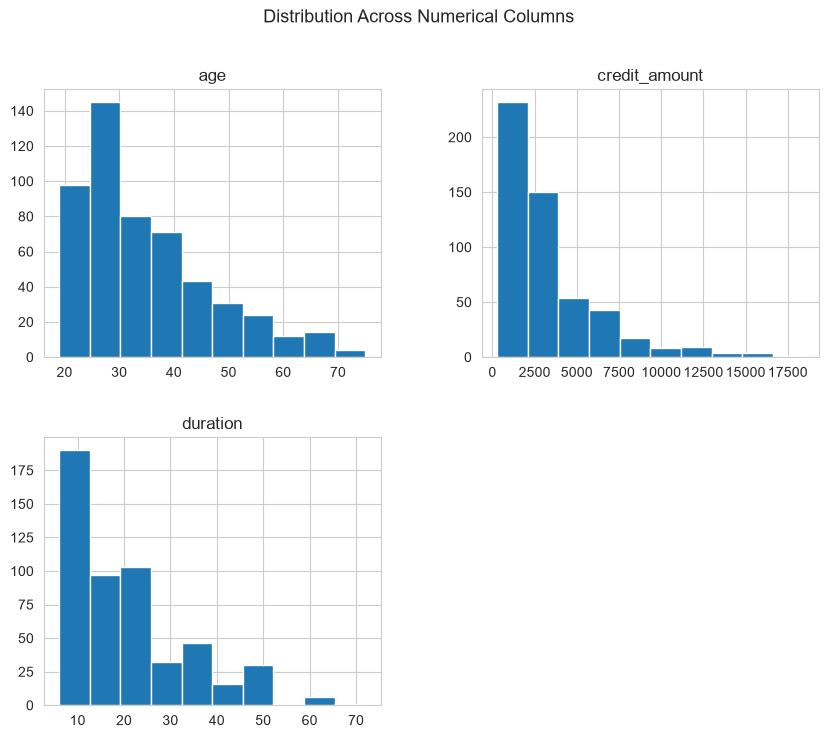

In [153]:
df[numerical_cols].hist(bins = 10, figsize=(10, 8))
plt.suptitle('Distribution Across Numerical Columns', fontsize= 13)

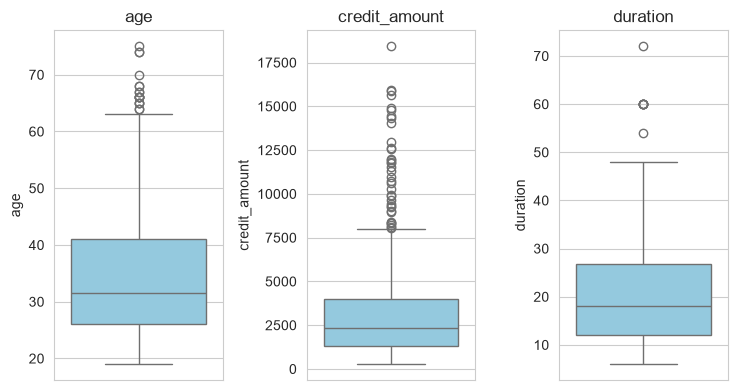

In [154]:
plt.figure(figsize=(10,4))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(f'{col}')

plt.tight_layout()
plt.show()

**Finding Outliers**

In [155]:
def catch_outlier(df: pd.DataFrame, numerical_cols: list[str], q1: pd.Series, q3: pd.Series, margin: float = 1.5) -> pd.DataFrame:
    iqr = q3 - q1
    print(iqr)

    lower_bound = q1 - margin * iqr
    upper_bound = q3 + margin * iqr
    
    iqr_thresholds = pd.DataFrame({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

    print(iqr_thresholds)

    normal_datapoints = df[(df[numerical_cols] >= lower_bound) & (df[numerical_cols] <= upper_bound)]
    outlier_mask = df[(df[numerical_cols] < lower_bound) | (df[numerical_cols] > upper_bound)]
    outlier_rows = outlier_mask.any(axis=1)

    outliers = df[outlier_rows]
    normal_datapoints = df[~outlier_rows]

    # Count the number of outliers in each column
    outlier_counts = outlier_mask.sum(axis=0)

    # Sort them in descending order to see the biggest culprits first
    print("Outliers per column:")
    print(outlier_counts.sort_values(ascending=False))

    # print(f"Normal Datapoints: {normal_datapoints}, \n Outliers: {outliers}")
    return lower_bound, upper_bound

q1 = df[numerical_cols].quantile(.25)
q3 = df[numerical_cols].quantile(.75)

fetch_lower_bound, fetch_upper_bound = catch_outlier(df, numerical_cols, q1, q3)

age               15.0000
credit_amount   2673.7500
duration          14.7500
dtype: float64
                     Q1        Q3       IQR  Lower Bound  Upper Bound
age             26.0000   41.0000   15.0000       3.5000      63.5000
credit_amount 1297.5000 3971.2500 2673.7500   -2713.1250    7981.8750
duration        12.0000   26.7500   14.7500     -10.1250      48.8750
Outliers per column:
credit_amount      414364.0000
age                  1216.0000
duration              486.0000
sex                          0
job                          0
housing                      0
saving_accounts              0
checking_account             0
purpose                      0
risk                         0
dtype: object


In [156]:
print(df['age'].min())
print(df['age'].max())

lower_age = fetch_lower_bound['age']
upper_age = fetch_upper_bound['age']
print(lower_age)
print(upper_age)

19
75
3.5
63.5


In [157]:
outliers = df[(df['age'] < 3.5) | (df['age'] > 63.5)]
print(f"Total outliers: {len(outliers)}")

Total outliers: 18


In [158]:
print(outliers['sex'].value_counts())

sex
male      13
female     5
Name: count, dtype: int64


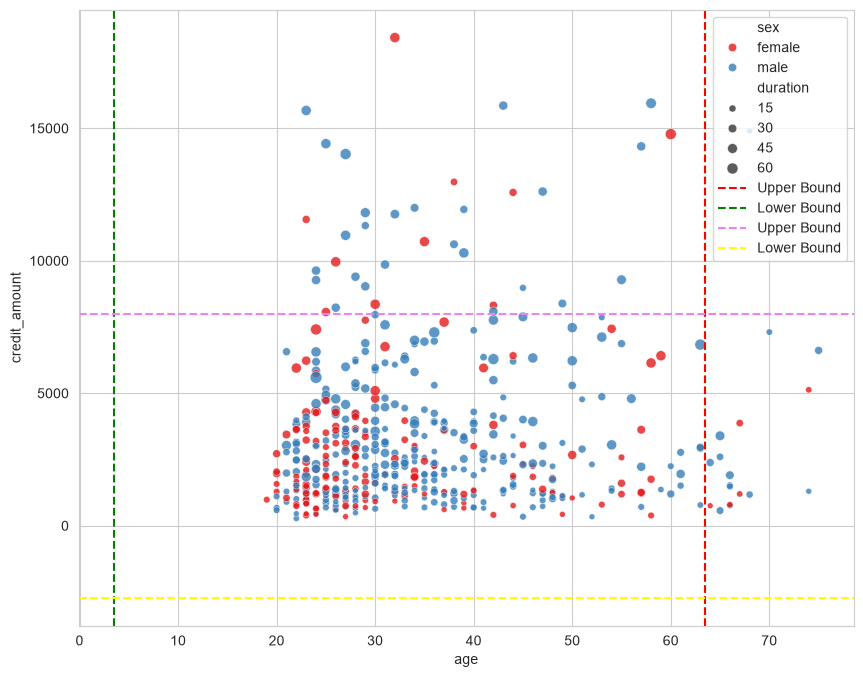

In [159]:
plt.figure(figsize=(10,8))
sns.scatterplot(df, x="age", y="credit_amount", hue='sex', size='duration', alpha=0.8, palette='Set1')
plt.axvline(x=fetch_upper_bound['age'], color='red', linestyle='--', label='Upper Bound')
plt.axvline(x=fetch_lower_bound['age'], color='green', linestyle='--', label='Lower Bound')
plt.axhline(y=fetch_upper_bound['credit_amount'], color='violet', linestyle='--', label='Upper Bound')
plt.axhline(y=fetch_lower_bound['credit_amount'], color='yellow', linestyle='--', label='Lower Bound')
plt.legend()
plt.show()

In [160]:
df.query("duration >= 60")

,age,sex,job,housing,saving_accounts,checking_account,credit_amount,duration,purpose,risk
29,63,male,Two,own,little,little,6836,60,business,bad
332,24,female,Three,own,moderate,moderate,7408,60,car,bad
374,60,female,Three,free,moderate,moderate,14782,60,vacation/others,bad
677,24,male,Two,own,moderate,moderate,5595,72,radio/TV,bad
714,27,male,Three,own,little,moderate,14027,60,car,bad
938,42,male,Two,free,little,moderate,6288,60,education,bad
973,36,male,Two,rent,little,little,7297,60,business,bad


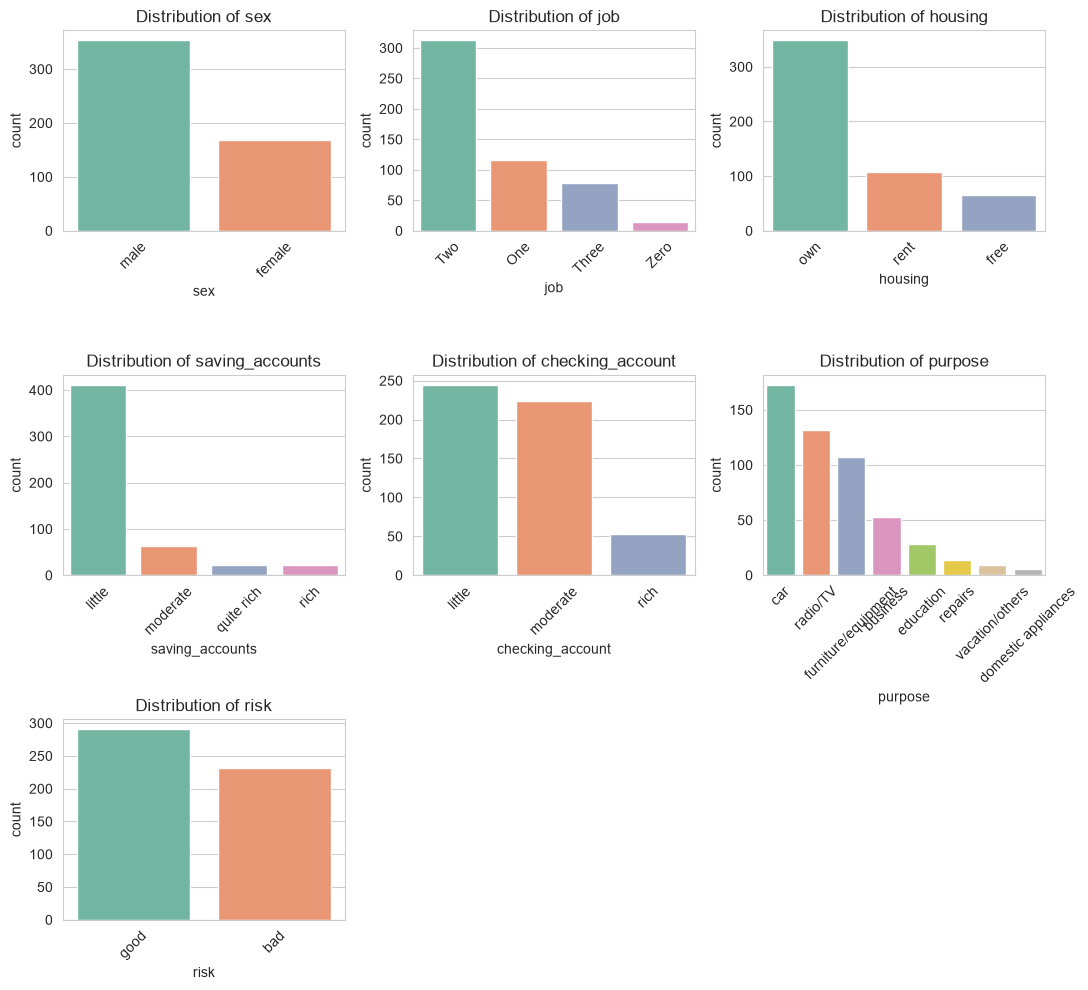

In [161]:
plt.figure(figsize=(11,  10))
for i, col in enumerate(categorical_col):
    plt.subplot(3, 3, i + 1)
    sns.countplot(data=df, x=col, palette='Set2', order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

**Check for correlation between numerical features**

<Axes: >

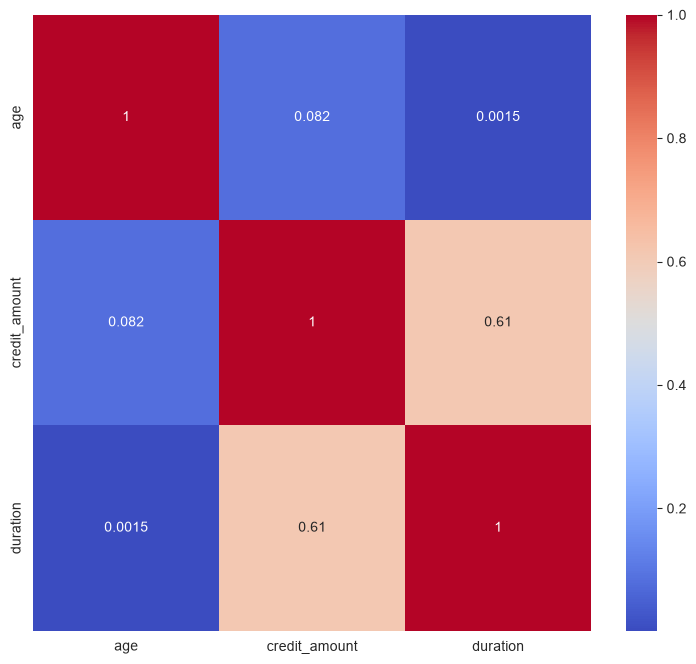

In [162]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')

In [163]:
# plt.figure(figsize=(10, 8))
# sns.pairplot(df, hue='risk', palette='Set2', diag_kind='kde')
# plt.show()

In [164]:
print(df.groupby('job')['credit_amount'].mean().sort_values(ascending=False))
print(df.groupby('sex')['credit_amount'].mean().sort_values(ascending=False))

job
Three   5648.7848
Two     3129.1310
One     2250.7155
Zero    1767.8571
Name: credit_amount, dtype: float64
sex
male     3440.8333
female   2937.2024
Name: credit_amount, dtype: float64


In [165]:
pd.pivot_table(df, values='credit_amount', index='housing', columns='purpose').T

housing,free,own,rent
purpose,,,
business,4705.0000,3725.9737,6180.8333
car,5180.3143,3120.4854,3398.2857
domestic appliances,NaN,1333.5000,NaN
education,5314.2500,2625.0769,2627.8571
furniture/equipment,4419.4444,3031.1000,2890.2857
radio/TV,2097.0000,2307.6139,2138.0000
repairs,1190.0000,2993.5000,2384.0000
vacation/others,7842.6667,10321.8333,NaN


In [166]:
age_corr = (df['credit_amount'].corr(df['age']) * 100)
print(age_corr)

8.20139343742943


In [167]:
# sns.violinplot(data = df, x = 'job', y = 'credit_amount', hue = 'sex', split = True, palette='Set2')
# plt.title('Credit Amount Distribution by Job and Sex')
# plt.show()

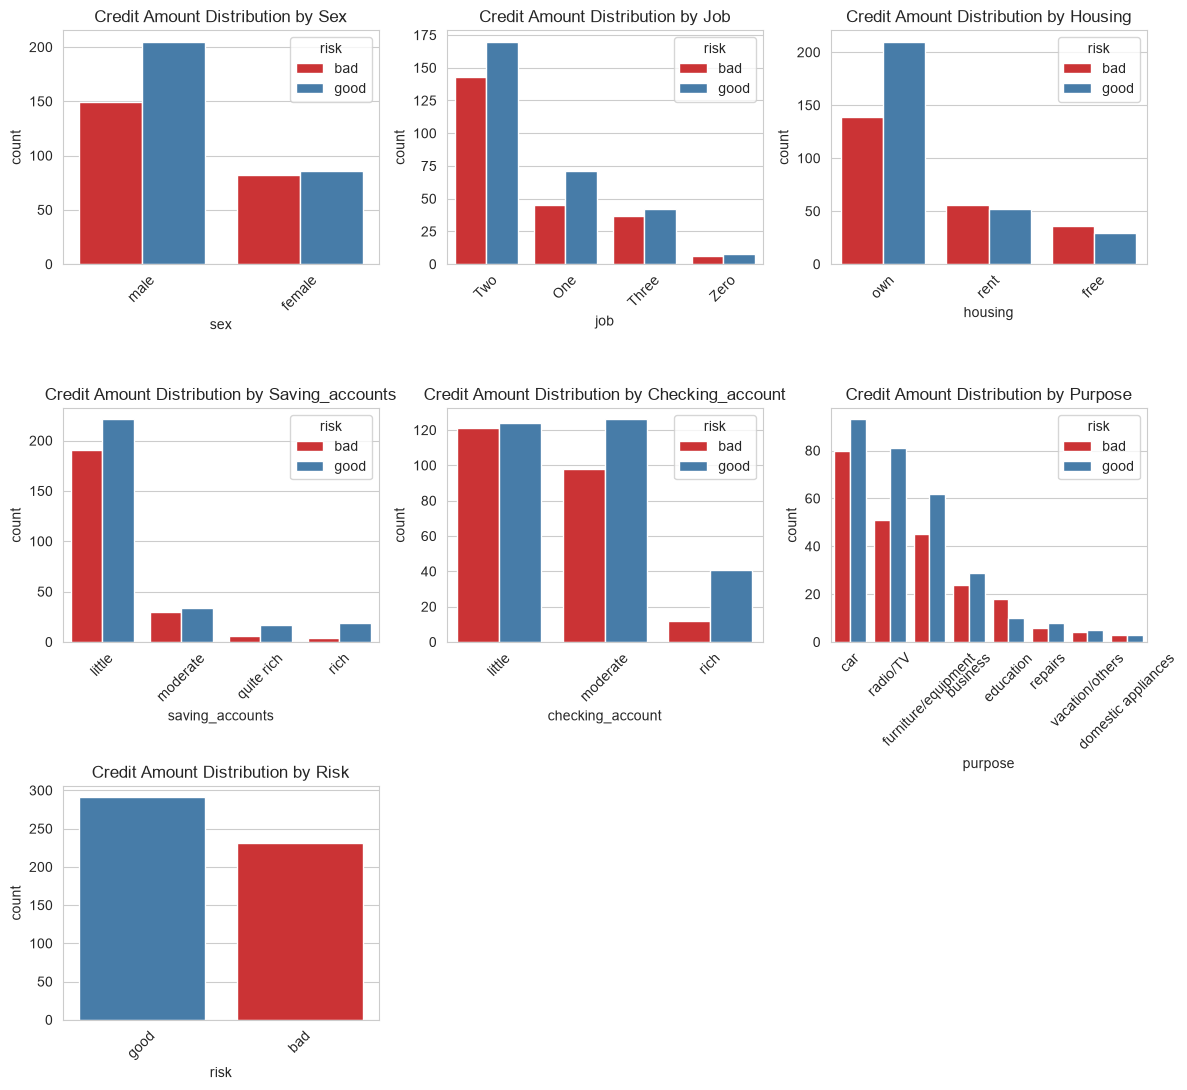

In [168]:
plt.figure(figsize=(12, 11))
for i, col in enumerate(categorical_col):
    plt.subplot(3, 3, i + 1)
    sns.countplot(data=df, x=col, hue = 'risk', palette='Set1', order=df[col].value_counts().index)
    plt.title(f'Credit Amount Distribution by {col.capitalize()}')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [169]:
features = ["age", "job", "credit_amount", "sex", "housing", "saving_accounts", "checking_account", "purpose"]
target = "risk"

In [170]:
df_model = df[features + [target]].copy()
df_model

,age,job,credit_amount,sex,housing,saving_accounts,checking_account,purpose,risk
1,22,Two,5951,female,own,little,moderate,radio/TV,bad
3,45,Two,7882,male,free,little,little,furniture/equipment,good
4,53,Two,4870,male,free,little,little,car,bad
7,35,Three,6948,male,rent,little,moderate,car,good
9,28,Three,5234,male,own,little,moderate,car,bad
...,...,...,...,...,...,...,...,...,...
989,48,One,1743,male,own,little,moderate,radio/TV,good
993,30,Three,3959,male,own,little,little,furniture/equipment,good
996,40,Three,3857,male,own,little,little,car,good
998,23,Two,1845,male,free,little,little,radio/TV,bad


**Encode Categorical Columns**

In [171]:
# %pip install -q scikit-learn
import joblib
from sklearn.preprocessing import LabelEncoder


In [172]:
cat_cols = df_model.select_dtypes(include=['object']).columns.drop(target).tolist()

In [173]:
label_encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le
    joblib.dump(le, PROCESSED_DATA_DIR/f"label_encoder_{col}.pkl")

label_encoders

{'job': LabelEncoder(),
 'sex': LabelEncoder(),
 'housing': LabelEncoder(),
 'saving_accounts': LabelEncoder(),
 'checking_account': LabelEncoder(),
 'purpose': LabelEncoder()}

In [174]:
label_encoder_target = LabelEncoder()
df_model[target] = label_encoder_target.fit_transform(df_model[target])
joblib.dump(label_encoder_target, PROCESSED_DATA_DIR/f"label_encoder_{target}.pkl")

['data\\processed\\label_encoder_risk.pkl']

In [175]:
df_model.head()

,age,job,credit_amount,sex,housing,saving_accounts,checking_account,purpose,risk
1,22,2,5951,0,1,0,1,5,0
3,45,2,7882,1,0,0,0,4,1
4,53,2,4870,1,0,0,0,1,0
7,35,1,6948,1,2,0,1,1,1
9,28,1,5234,1,1,0,1,1,0


In [176]:
print(df_model[target].value_counts())

risk
1    291
0    231
Name: count, dtype: int64


In [177]:
from sklearn.model_selection import train_test_split

In [178]:
X = df_model.drop(columns = target)
y = df_model[target]

In [179]:
X_train, X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=.2,
    random_state=RANDOM_STATE,
    stratify=y    
)

In [180]:
# %pip install -q xgboost

**Load all modeling dependencies**

In [181]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier


In [182]:
def train_model(model, grid, X_train, y_train, X_test, y_test):
    grid = GridSearchCV(model, grid, cv = 5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred) * 100
    return best_model, acc, grid.best_params_

**DECISION TREE CLASSIFIER**

In [183]:
decision_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced")
dt_param_grid = {
    "max_depth": [3,5,7,10, None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [184]:
best_dt, acc_dt, params_dt = train_model(decision_tree, dt_param_grid, X_train, y_train, X_test, y_test)

In [185]:
print(f"Best Model: {best_dt}")
print(f"Best Parameters: {params_dt}")
print(f"Best Accuracy: {acc_dt}")

Best Model: DecisionTreeClassifier(class_weight='balanced', random_state=42)
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Accuracy: 56.19047619047619


**RANDOM FOREST CLASSIFIER**

In [186]:
rf_MODEL = RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)

In [187]:
rf_param_grid = {
 "n_estimators": [100, 200],
 "max_depth" : [5, 7, 10, None],
 "min_samples_split": [2,5,10],
 "min_samples_leaf":[1,2,4]    
}

In [188]:
best_rf, acc_rf, params_rf = train_model(
    rf_MODEL, rf_param_grid, X_train, y_train, X_test, y_test)

In [189]:
print(f"Best Model: {best_rf}")
print(f"Best Parameters: {params_rf}")
print(f"Best Accuracy: {acc_rf}")

Best Model: RandomForestClassifier(class_weight='balanced', max_depth=5,
                       min_samples_split=10, n_estimators=200, n_jobs=-1,
                       random_state=42)
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best Accuracy: 60.0


**EXTRA TREE CLASSIFIER**

In [190]:

extraTree = ExtraTreesClassifier(random_state = RANDOM_STATE, class_weight = "balanced", n_jobs = -1)

In [191]:
et_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [192]:
best_et, acc_et, params_et = train_model(
    extraTree, et_param_grid, X_train, y_train, X_test, y_test)

In [193]:
print(f"Best Model: {best_et}")
print(f"Best Parameters: {params_et}")
print(f"Best Accuracy: {acc_et}")

Best Model: ExtraTreesClassifier(class_weight='balanced', max_depth=7, min_samples_leaf=4,
                     n_estimators=200, n_jobs=-1, random_state=42)
Best Parameters: {'max_depth': 7, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}
Best Accuracy: 56.19047619047619


**XGBOOST**

In [194]:
xgb = XGBClassifier(random_state = 1, scale_pos_weight = ((y_train ==0).sum() / (y_train ==1).sum()), use_label_encoder = False, eval_metric = "logloss")

In [195]:
xgb_param_grid = {
    "n_estimators":[100,200],
    "max_depth": [3,5,7],
    "learning_rate":[0.01, 0.1, 0.2],
    "subsample":[0.7, 1],
    "colsample_bytree": [0.7, 1]
}

In [196]:
best_xgb, acc_xgb, params_xgb = train_model(
    xgb, xgb_param_grid, X_train, y_train, X_test, y_test)

In [197]:
print(f"Best Model: {best_xgb}")
print(f"Best Parameters: {params_xgb}")
print(f"Best Accuracy: {acc_xgb}")

Best Model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)
Best Parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.7}
Best Accuracy: 61.904761904761905


**OVERALL PERFORMANCE**

<Axes: title={'center': 'Model Accuracy Comparison'}, xlabel='Model', ylabel='Accuracy (%)'>

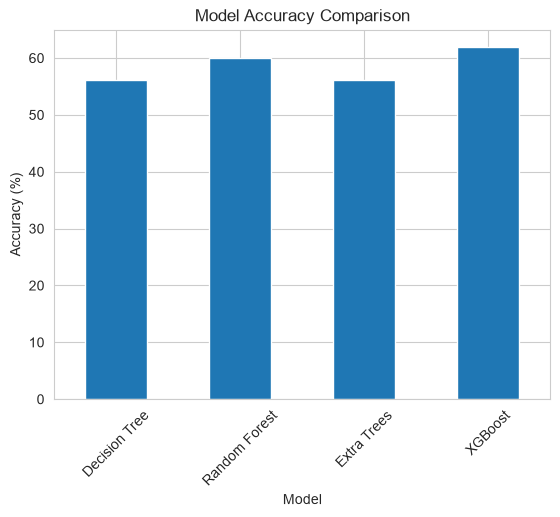

In [198]:
model_performance = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "Extra Trees", "XGBoost"],
    "Accuracy (%)": [acc_dt, acc_rf, acc_et, acc_xgb]
})

model_performance.set_index("Model")["Accuracy (%)"].plot(
    kind="bar",
    title="Model Accuracy Comparison",
    ylabel="Accuracy (%)",
    xlabel="Model",
    rot=45,
    legend=False
)

In [200]:
joblib.dump(best_xgb, OUTPUT_DIR/"xgb_credit_model.pkl")

['outputs\\xgb_credit_model.pkl']